In [1]:
import numpy as np

print("Numpy version:", np.__version__)

Numpy version: 2.5.4


In [2]:
# Bagian A
# Fungsi Metrik Jarak

def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def manhattan_distance(a, b):
    return np.sum(np.abs(a - b))

def minkowski_distance(a, b, p):
    return np.sum(np.abs(a - b) ** p) ** (1 / p)

In [3]:
# data uji sederhana dengan 2 fitur
data_A = np.array([1, 2])
data_B = np.array([4, 6])

print("Euclidean:", euclidean_distance(data_A, data_B))
print("Manhattan:", manhattan_distance(data_A, data_B))
print("Minkowski (p=2):", minkowski_distance(data_A, data_B, p=2))

Euclidean: 5.0
Manhattan: 7
Minkowski (p=2): 5.0


In [4]:
# bagian A
# Fungsi Normalisasi Data


def min_max_scaler(X_train, X_test):
    min_val = np.min(X_train, axis=0)
    max_val = np.max(X_train, axis=0)
    X_train_scaled = (X_train - min_val) / (max_val - min_val)
    X_test_scaled = (X_test - min_val) / (max_val - min_val)
    return X_train_scaled, X_test_scaled


def z_score_scaler(X_train, X_test):
    mean = np.mean(X_train, axis=0)
    std = np.std(X_train, axis=0)
    X_train_scaled = (X_train - mean) / std
    X_test_scaled = (X_test - mean) / std
    return X_train_scaled, X_test_scaled

In [5]:
# Data uji untuk normalisasi

X_train = np.array([[10, 100], [20, 200]])
X_test = np.array([[15, 150]])

X_train_minmax, X_test_minmax = min_max_scaler(X_train, X_test)
print("MinMax Scaled Train:\n", X_train_minmax)
print("MinMax Scaled Test:\n", X_test_minmax)

MinMax Scaled Train:
 [[0. 0.]
 [1. 1.]]
MinMax Scaled Test:
 [[0.5 0.5]]


In [6]:
# bagian A

import numpy as np

class KNNClassifier:
    def __init__(self, k=3, metric="euclidean", p=2, weights="uniform"):
        self.k = k
        self.metric = metric
        self.p = p
        self.weights = weights
        
    def fit(self, X, y):
        # Menyimpan data latih
        self.X_train = np.array(X)
        self.y_train = np.array(y)
        
    def _distance(self, a, b):
        # Memanggil logika jarak
        if self.metric == "euclidean":
            return euclidean_distance(a, b)
        elif self.metric == "manhattan":
            return manhattan_distance(a, b)
        elif self.metric == "minkowski":
            return minkowski_distance(a, b, self.p)

    def predict(self, X_test):
        X_test = np.array(X_test)
        predictions = []
        
        for x in X_test:
            # Hitung jarak x ke setiap data di X_train
            distances = np.array([self._distance(x, x_tr) for x_tr in self.X_train])
            
            # Cari K indeks tetangga terdekat
            k_indices = np.argsort(distances)[:self.k]
            k_labels = self.y_train[k_indices]
            k_distances = distances[k_indices]
            
            # Voting (Uniform atau Distance)
            if self.weights == "uniform":
                # Cari kelas yang paling banyak muncul
                classes, counts = np.unique(k_labels, return_counts=True)
                max_count = np.max(counts)
                winning_classes = classes[counts == max_count]
                
                # Tie-Breaking Rule
                # Jika ada lebih dari 1 kelas pemenang, ambil kelas dari tetangga terdekat individual
                if len(winning_classes) > 1:
                    for label in k_labels:
                        if label in winning_classes:
                            final_pred = label
                            break
                else:
                    final_pred = winning_classes[0]
                    
            elif self.weights == "distance":
                # Hitung bobot = 1 / d^2
                # menghidari pembagian dengan nol dengan menambahkan epsilon kecil (1e-10)
                weights_val = 1.0 / (np.maximum(k_distances, 1e-10) ** 2)
                
                class_weights = {}
                for label, w in zip(k_labels, weights_val):
                    class_weights[label] = class_weights.get(label, 0.0) + w
                
                # Pilih kelas dengan total bobot terbesar
                final_pred = max(class_weights, key=class_weights.get)
                
            predictions.append(final_pred)
            
        return np.array(predictions)

In [7]:
# data latih studi kasus

X_train_studi = np.array([
    [85, 80], [60, 55], [75, 70], [50, 65],
    [90, 85], [65, 50], [70, 75], [55, 60]
])

y_train_studi = np.array([
    "Lulus", "Tidak Lulus", "Lulus", "Tidak Lulus",
    "Lulus", "Tidak Lulus", "Lulus", "Tidak Lulus"
])

# data uji mahasiswa x 
X_test_studi = np.array([[68, 64]])

# test k = 3, uniform
knn1 = KNNClassifier(k=3, metric="euclidean", weights="uniform")
knn1.fit(X_train_studi, y_train_studi)
print("Prediksi (k=3, uniform):", knn1.predict(X_test_studi))

# test k = 5, uniform
knn2 = KNNClassifier(k=5, metric="euclidean", weights="uniform")
knn2.fit(X_train_studi, y_train_studi)
print("Prediksi (k=5, uniform):", knn2.predict(X_test_studi))

# test k = 5, weighted
knn3 = KNNClassifier(k=5, metric="euclidean", weights="distance")
knn3.fit(X_train_studi, y_train_studi)
print("Prediksi (k=5, weighted):", knn3.predict(X_test_studi))


Prediksi (k=3, uniform): ['Lulus']
Prediksi (k=5, uniform): ['Tidak Lulus']
Prediksi (k=5, weighted): ['Lulus']


In [11]:
# Bagian B


import numpy as np
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import time

# Load dataset breast cancer
data = load_breast_cancer()
X = data.data
y = data.target

# bagi dataset menjadi 80% data latih dan 20% data uji
# nim digit terakhir = 07, random_state = 7
NIM_SEED = 7
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=NIM_SEED, stratify=y)

# Latih knn buatan sendiri dengan k=5, euclidean, uniform
knn_custom = KNNClassifier(k=5, metric="euclidean", weights="uniform")
knn_custom.fit(X_train, y_train)
y_predict_custom = knn_custom.predict(X_test)

# Latih knn sklearn dengan k=5, euclidean, uniform
knn_sklearn = KNeighborsClassifier(n_neighbors=5, metric="euclidean", weights="uniform")
knn_sklearn.fit(X_train, y_train)
y_predict_sklearn = knn_sklearn.predict(X_test)

# hitung presentase kesamaan prediksi
match_precentage = np.mean(y_predict_custom == y_predict_sklearn) * 100
print(f"Presentase kesamaan prediksi: {match_precentage:.2f}%")

# cek apakah ada data prediksi yang berbeda
defferences = np.where(y_predict_custom != y_predict_sklearn)[0]
if len(defferences) == 0:
    print("Semua prediksi sama antara knn buatan sendiri dan sklearn.")
else:
    print(f"Ada {len(defferences)} prediksi yang berbeda antara knn buatan sendiri dan sklearn.")
    print("Indeks data yang berbeda:", defferences)
    print("Prediksi knn buatan sendiri:", y_predict_custom[defferences])
    print("Prediksi knn sklearn:", y_predict_sklearn[defferences])

# Hitung waktu prediksi KNN buatan sendiri pada X_test utama
start_custom = time.time()
y_pred_custom = knn_custom.predict(X_test)
end_custom = time.time()
waktu_custom = end_custom - start_custom

# Hitung waktu prediksi KNN Scikit-Learn pada X_test utama
start_sklearn = time.time()
y_pred_sklearn = knn_sklearn.predict(X_test)
end_sklearn = time.time()
waktu_sklearn = end_sklearn - start_sklearn

print(f"Waktu prediksi implementasi sendiri : {waktu_custom:.6f} detik")
print(f"Waktu prediksi scikit-learn        : {waktu_sklearn:.6f} detik")


Presentase kesamaan prediksi: 100.00%
Semua prediksi sama antara knn buatan sendiri dan sklearn.
Waktu prediksi implementasi sendiri : 0.395907 detik
Waktu prediksi scikit-learn        : 0.009139 detik


In [9]:
# Bagian C

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# list parameter eksperimen
k_list = [3, 5, 7, 9]
metrics = ["euclidean", "manhattan"]
scaling_methods = ["Tanpa Normalisasi", "Min-Max", "Z-Score"]

results = []

# loop kombinasi eksperimen
for scale in scaling_methods:
    if scale == "Tanpa Normalisasi":
        X_train_eksperimen, X_test_scaled = X_train, X_test
    elif scale == "Min-Max":
        X_train_eksperimen, X_test_scaled = min_max_scaler(X_train, X_test)
    elif scale == "Z-Score":
        X_train_eksperimen, X_test_scaled = z_score_scaler(X_train, X_test)

for metric in metrics:
    for k in k_list:
        # latih knn buatan sendiri
        knn_custom = KNNClassifier(k=k, metric=metric, weights="uniform")
        knn_custom.fit(X_train_eksperimen, y_train)
        y_predict_custom = knn_custom.predict(X_test_scaled)

        # hitung metrik evaluasi (macro average)
        accuracy = accuracy_score(y_test, y_predict_custom)
        precision = precision_score(y_test, y_predict_custom, average='macro')
        recall = recall_score(y_test, y_predict_custom, average='macro')
        f1 = f1_score(y_test, y_predict_custom, average='macro')

        # simpan hasil eksperimen
        results.append({
            "Normalisasi": scale,
            "Metrik": metric,
            "K": k,
            "Akurasi (%)": round(accuracy * 100, 2),
            "Presisi (%)": round(precision * 100, 2),
            "Recall (%)": round(recall * 100, 2),
            "F1-Score (%)": round(f1 * 100, 2)
        })

# dataframe hasil eksperimen
results_df = pd.DataFrame(results)

display(results_df)

,Normalisasi,Metrik,K,Akurasi (%),Presisi (%),Recall (%),F1-Score (%)
0,Z-Score,euclidean,3,97.37,98.00,96.43,97.13
1,Z-Score,euclidean,5,98.25,98.65,97.62,98.10
2,Z-Score,euclidean,7,97.37,98.00,96.43,97.13
3,Z-Score,euclidean,9,96.49,97.37,95.24,96.15
4,Z-Score,manhattan,3,97.37,98.00,96.43,97.13
5,Z-Score,manhattan,5,97.37,98.00,96.43,97.13
6,Z-Score,manhattan,7,97.37,98.00,96.43,97.13
7,Z-Score,manhattan,9,96.49,97.37,95.24,96.15


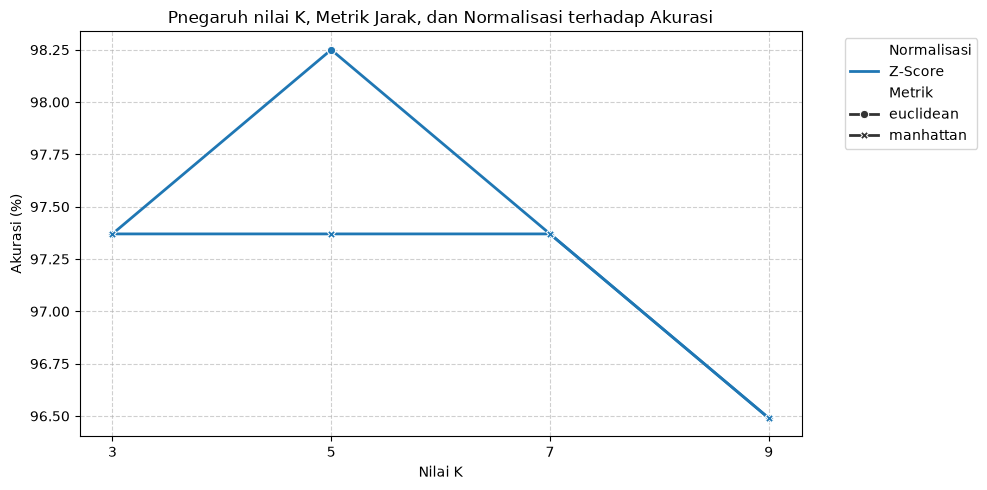


Konfigurasi terbaik:
Normalisasi       Z-Score
Metrik          euclidean
K                       5
Akurasi (%)         98.25
Presisi (%)         98.65
Recall (%)          97.62
F1-Score (%)         98.1
Name: 1, dtype: object


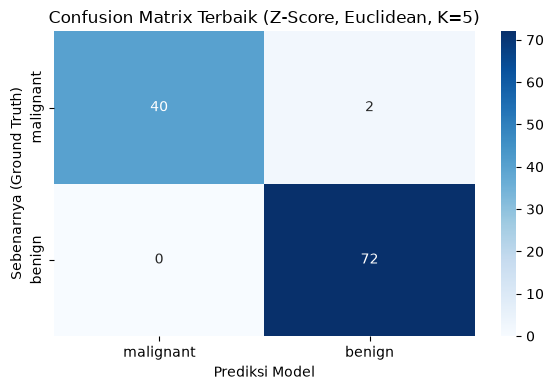

In [10]:
# Bagian C
# Visualisasi Hasil Eksperimen

# grafik k vs akurasi berdasarkan skala dan metrik
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=results_df, 
    x='K', 
    y='Akurasi (%)', 
    hue='Normalisasi', 
    style='Metrik', 
    markers=True, 
    dashes=False,
    linewidth=2
)

plt.title('Pnegaruh nilai K, Metrik Jarak, dan Normalisasi terhadap Akurasi', fontsize=12)
plt.xlabel('Nilai K', fontsize=10)
plt.ylabel('Akurasi (%)', fontsize=10)
plt.xticks(k_list)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('../results/knn_experiment_results.png', dpi=300)
plt.show()

# cari konfigurasi terbaik
best_config = results_df.loc[results_df['Akurasi (%)'].idxmax()]
print("\nKonfigurasi terbaik:")
print(best_config)

# Visualisasi Confusion Matrix untuk konfigurasi terbaik
best_scale = best_config['Normalisasi']
best_metric = best_config['Metrik']
best_k = best_config['K']

if best_scale == "Tanpa Normalisasi":
    X_train_best, X_test_best = X_train.copy(), X_test.copy()
elif best_scale == "Min-Max":
    X_train_best, X_test_best = min_max_scaler(X_train, X_test)
elif best_scale == "Z-Score":
    X_train_best, X_test_best = z_score_scaler(X_train, X_test)

best_knn = KNNClassifier(k = best_k, metric = best_metric, weights = "uniform")
best_knn.fit(X_train_best, y_train)
y_predict_best = best_knn.predict(X_test_best)

confusion_mat = confusion_matrix(y_test, y_predict_best)

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='Blues', xticklabels=data.target_names, yticklabels=data.target_names)
plt.title(f'Confusion Matrix Terbaik ({best_scale}, {best_metric.capitalize()}, K={best_k})')
plt.xlabel('Prediksi Model')
plt.ylabel('Sebenarnya (Ground Truth)')
plt.tight_layout()
plt.savefig('../results/figures/confusion_matrix.png', dpi=300)
plt.show()